In [70]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

from IPython.display import display

In [2]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)

print(df.head())
print(df.shape)

      lead_source       industry employment_status       location  \
0  organic_search     technology          employed         europe   
1    social_media     technology          employed  south_america   
2        referral         retail          employed         europe   
3        paid_ads  manufacturing           student            NaN   
4        referral  manufacturing           student  north_america   

   annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0        88160.0                         3                  4        0.64   
1        72688.0                         3                  7        0.72   
2        44697.0                         3                  4        0.58   
3            NaN                         3                  6        0.57   
4        24062.0                         4                  5        0.62   

   converted  
0          1  
1          1  
2          1  
3          0  
4          1  
(5000, 9)


In [3]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [4]:
df.converted.value_counts(normalize=True)

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64

In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [33]:
str_cols = df.select_dtypes(include=['str']).columns.tolist()
numerical_cols =df.select_dtypes(include=['number']).columns.drop('converted').tolist()
str_cols, numerical_cols

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score'])

list

In [8]:
df[str_cols] = df[str_cols].fillna('NA')
df[numerical_cols] = df[numerical_cols].fillna(0.0)

In [22]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [23]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [24]:
from sklearn.metrics import roc_auc_score

In [25]:
numerical = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]

for col in numerical:
    auc = roc_auc_score(df_train['converted'], df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(df_train['converted'], -df_train[col])

    print(col, round(auc, 3))

lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


In [26]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [27]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [35]:
dv = DictVectorizer(sparse=False)
train_dicts = df_train[str_cols + numerical_cols].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[str_cols + numerical_cols].to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [41]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [45]:
y_pred = model.predict_proba(X_val)[:, 1]
y_pred

array([0.54472295, 0.79005198, 0.50977894, 0.52913941, 0.82072021,
       0.54245984, 0.50178714, 0.54698389, 0.82553294, 0.40583738,
       0.91301564, 0.33581817, 0.3078987 , 0.42704785, 0.62192281,
       0.53665458, 0.41931923, 0.84087341, 0.79969125, 0.61790114,
       0.61625179, 0.6805992 , 0.85605897, 0.80784867, 0.62046006,
       0.4597071 , 0.54556707, 0.4122138 , 0.72714013, 0.46812075,
       0.77222181, 0.79043877, 0.61433884, 0.7854975 , 0.49753412,
       0.66077277, 0.69804754, 0.76896541, 0.65657492, 0.64127896,
       0.66509104, 0.57942811, 0.67830936, 0.61186099, 0.86890227,
       0.41469667, 0.84130125, 0.74229356, 0.68028535, 0.71891428,
       0.86417926, 0.64043359, 0.54246983, 0.7022515 , 0.27894891,
       0.70826481, 0.623107  , 0.47781752, 0.37914015, 0.6993603 ,
       0.52032858, 0.69977692, 0.75148935, 0.58087489, 0.47001791,
       0.56863475, 0.9129718 , 0.79972021, 0.82206541, 0.36140189,
       0.66132389, 0.52330049, 0.79295461, 0.72068071, 0.71234

In [46]:
auc = roc_auc_score(y_val, y_pred)

round(auc, 3)

0.732

In [55]:
from sklearn.metrics import roc_curve, auc, precision_score, recall_score

In [48]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

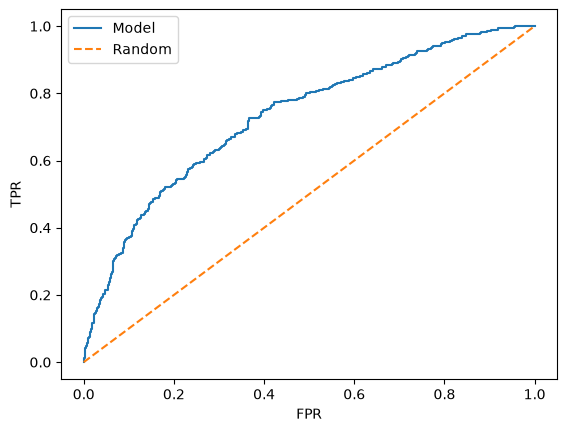

In [50]:
plt.Figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0,1], label='Random', linestyle='--')


plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()


In [53]:
round(auc(fpr, tpr), 3)

0.732

#### Q3

In [64]:
thresholds = np.arange(0, 1, 0.01)

precisions = []
recalls = []

for t in thresholds:
    # Convert probabilities into 0/1 predictions
    y_pred_binary = (y_pred >= t).astype(int)

    # Calculate precision and recall
    p = precision_score(y_val, y_pred_binary, zero_division=0)
    r = recall_score(y_val, y_pred_binary, zero_division=0)

    precisions.append(p)
    recalls.append(r)

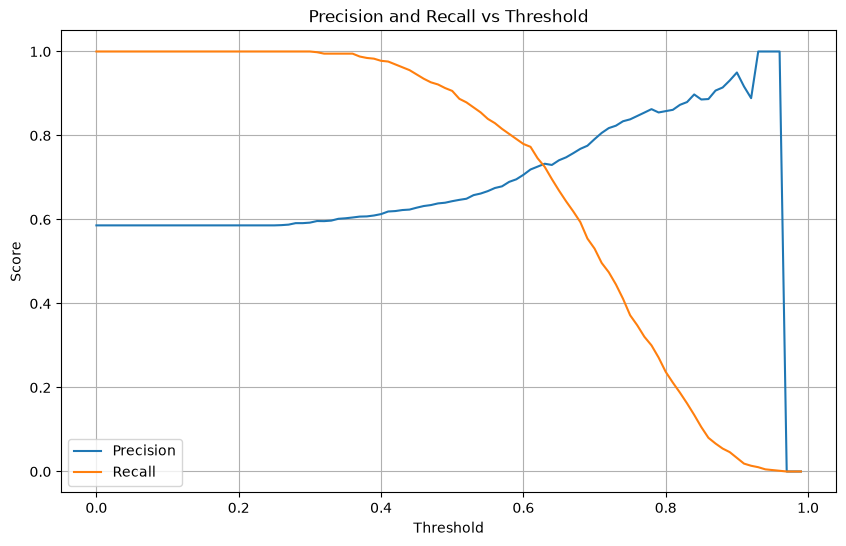

In [65]:
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid()
plt.show()

In [66]:
precisions = np.array(precisions)
recalls = np.array(recalls)

valid = (precisions != 0) | (recalls != 0)

diff = np.abs(precisions - recalls)
diff[~valid] = np.inf

best_idx = np.argmin(diff)

print("Threshold:", thresholds[best_idx])
print("Precision:", precisions[best_idx])
print("Recall:", recalls[best_idx])
print("Difference:", diff[best_idx])

Threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458
Difference: 0.007502647993409384


#### Q4

In [67]:
f1_scores = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    p = precision_score(y_val, y_pred_binary, zero_division=0)
    r = recall_score(y_val, y_pred_binary, zero_division=0)

    if p + r == 0:
        f1 = 0
    else:
        f1 = 2 * p * r / (p + r)

    f1_scores.append(f1)

In [69]:
best_idx = np.argmax(f1_scores)

print("Best threshold:", thresholds[best_idx])
print("Maximum F1 score:", round(f1_scores[best_idx], 3))

Best threshold: 0.41000000000000003
Maximum F1 score: 0.758


#### Q5

In [72]:
from sklearn.model_selection import KFold

In [73]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_fold_train = df_full_train.iloc[train_idx]
    df_fold_val = df_full_train.iloc[val_idx]

    y_fold_train = df_fold_train['converted'].values
    y_fold_val = df_fold_val['converted'].values

    train_dicts = df_fold_train[str_cols + numerical_cols].to_dict(orient='records')
    val_dicts = df_fold_val[str_cols + numerical_cols].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_fold_train = dv.fit_transform(train_dicts)
    X_fold_val = dv.transform(val_dicts)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_fold_train, y_fold_train)

    y_pred = model.predict_proba(X_fold_val)[:, 1]
    auc = roc_auc_score(y_fold_val, y_pred)

    scores.append(auc)

    print(f"AUC: {auc:.3f}")

print("Mean:", np.mean(scores))
print("Standard deviation:", np.std(scores))

AUC: 0.731
AUC: 0.730
AUC: 0.736
AUC: 0.741
AUC: 0.721
Mean: 0.7317269710972524
Standard deviation: 0.006853233151022138


#### Q6

In [74]:
C_values = [0.000001, 0.001, 1]

results = []

for C in C_values:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        y_fold_train = df_fold_train['converted'].values
        y_fold_val = df_fold_val['converted'].values

        cols = str_cols + numerical_cols

        train_dicts = df_fold_train[cols].to_dict(orient='records')
        val_dicts = df_fold_val[cols].to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_fold_train = dv.fit_transform(train_dicts)
        X_fold_val = dv.transform(val_dicts)

        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model.fit(X_fold_train, y_fold_train)

        y_pred = model.predict_proba(X_fold_val)[:, 1]
        auc = roc_auc_score(y_fold_val, y_pred)

        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    results.append({
        'C': C,
        'mean_auc': round(mean_auc, 3),
        'std_auc': round(std_auc, 3)
    })

print(pd.DataFrame(results))

          C  mean_auc  std_auc
0  0.000001     0.617    0.019
1  0.001000     0.749    0.010
2  1.000000     0.732    0.007
